# Cricket Match Analyzer 

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

### Part_1
.....Data Loading

In [50]:
df = pd.read_csv('Cricket_data.csv')

In [67]:
df.head()

,Match_ID,Date,Batter,Bowler,Runs_Scored,Balls_Faced,Wickets_Taken,Runs_Conceded,Balls_Bowled,Phase,Opponent,Strike_Rate,Overs_Bowled,Economy_Rate
0,1,2024-05-11,Suryakumar Yadav,NaN,58,40,0,0,0,Powerplay,Australia,145.0,0.0,0.00
1,1,2024-05-11,Rohit Sharma,NaN,9,20,0,0,0,Middle Overs,Australia,45.0,0.0,0.00
2,1,2024-05-11,NaN,Hardik Pandya,0,0,1,35,24,Middle Overs,Australia,0.0,4.0,8.75
3,1,2024-05-11,NaN,Jasprit Bumrah,0,0,2,24,12,Death Overs,Australia,0.0,2.0,12.00
4,2,2024-12-06,Suryakumar Yadav,NaN,35,35,0,0,0,Powerplay,South Africa,100.0,0.0,0.00


In [84]:
df.tail()

,Match_ID,Date,Batter,Bowler,Runs_Scored,Balls_Faced,Wickets_Taken,Runs_Conceded,Balls_Bowled,Phase,Opponent,Strike_Rate,Overs_Bowled,Economy_Rate,Bowling_Strike_Rate,Run_Rate,Bowling_Average
1000,131,2024-03-18,Rohit Sharma,NaN,40,14,0,0,0,Middle Overs,England,285.714286,0.0,0.0,0.0,17.142857,0.0
1001,185,2024-12-09,Rohit Sharma,NaN,22,30,0,0,0,Middle Overs,South Africa,73.333333,0.0,0.0,0.0,4.400000,0.0
1002,186,2024-12-27,Virat Kohli,NaN,54,11,0,0,0,Powerplay,Australia,490.909091,0.0,0.0,0.0,29.454545,0.0
1003,166,2024-11-24,Rohit Sharma,NaN,12,17,0,0,0,Powerplay,England,70.588235,0.0,0.0,0.0,4.235294,0.0
1004,103,2024-12-23,NaN,Hardik Pandya,0,0,3,21,12,Death Overs,England,0.000000,2.0,10.5,4.0,0.000000,7.0


In [83]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Match_ID             1005 non-null   int64         
 1   Date                 1005 non-null   datetime64[us]
 2   Batter               504 non-null    str           
 3   Bowler               501 non-null    str           
 4   Runs_Scored          1005 non-null   int64         
 5   Balls_Faced          1005 non-null   int64         
 6   Wickets_Taken        1005 non-null   int64         
 7   Runs_Conceded        1005 non-null   int64         
 8   Balls_Bowled         1005 non-null   int64         
 9   Phase                1005 non-null   str           
 10  Opponent             1005 non-null   str           
 11  Strike_Rate          1005 non-null   float64       
 12  Overs_Bowled         1005 non-null   float64       
 13  Economy_Rate         1005 non-null   float64

### Part_3
.....Data Cleaning

##### Dupilicate Rows

In [85]:
print(f"\nRows before dropping duplicates: {len(df)}")
df = df.drop_duplicates()
print(f"Rows after dropping duplicates: {len(df)}")


Rows before dropping duplicates: 1005
Rows after dropping duplicates: 1000


##### Check missing values

In [ ]:

print("\nMissing values:\n", df.isnull().sum())


Missing values:
 Match_ID                 0
Date                     0
Batter                 500
Bowler                 500
Runs_Scored              0
Balls_Faced              0
Wickets_Taken            0
Runs_Conceded            0
Balls_Bowled             0
Phase                    0
Opponent                 0
Strike_Rate              0
Overs_Bowled             0
Economy_Rate             0
Bowling_Strike_Rate      0
Run_Rate                 0
Bowling_Average          0
dtype: int64


##### Correct spelling mistake (Powerplae -> Powerplay)

In [ ]:

df['Phase'] = df['Phase'].replace({'Powerplae': 'Powerplay'})

##### Convert Date column into datetime format

In [ ]:

df['Date'] = pd.to_datetime(df['Date'])

##### before conversion

In [89]:
print(f"🔹 Datatype BEFORE conversion : {df['Date'].dtype}")
print("   Sample values:")
print(df['Date'].head(3))

🔹 Datatype BEFORE conversion : datetime64[us]
   Sample values:
0   2024-05-11
1   2024-05-11
2   2024-05-11
Name: Date, dtype: datetime64[us]


##### After conversion

In [91]:
print(f"✅ Datatype AFTER conversion  : {df['Date'].dtype}")
print("   Sample values (Structured) :")
print(df['Date'].head(3))

print("=" * 50)

✅ Datatype AFTER conversion  : datetime64[us]
   Sample values (Structured) :
0   2024-05-11
1   2024-05-11
2   2024-05-11
Name: Date, dtype: datetime64[us]


##### Perform the conversion

In [ ]:

df['Date'] = pd.to_datetime(df['Date'])

print("-" * 50)

--------------------------------------------------


In [52]:
top_batsman = df.groupby('Batter')['Runs_Scored'].sum().idxmax()
max_runs = df.groupby('Batter')['Runs_Scored'].sum().max()

### Part 3
.....Data Processing

##### Data Validation Check

In [ ]:

print("🔹 Column Datatypes Verification:")
print(df[['Strike_Rate', 'Overs_Bowled', 'Economy_Rate']].dtypes)
print("-" * 65)


🔹 Column Datatypes Verification:
Strike_Rate     float64
Overs_Bowled    float64
Economy_Rate    float64
dtype: object
-----------------------------------------------------------------


##### Strike Rate

In [ ]:

print(f"{'Player Name':<20} | {'Total Runs':<10} | {'Balls Faced':<11} | {'Avg Strike Rate':<15}")
print("-" * 65)
for player, row in batter_preview.iterrows():
    print(f"{player:<20} | {int(row['Runs_Scored']):<10} | {int(row['Balls_Faced']):<11} | {row['Strike_Rate']:<15.2f}")

print("=" * 65)

Player Name          | Total Runs | Balls Faced | Avg Strike Rate
-----------------------------------------------------------------
Virat Kohli          | 4316       | 3052        | 174.89         
Rohit Sharma         | 4299       | 2794        | 184.11         
Suryakumar Yadav     | 4285       | 3012        | 175.61         


#####  Econamy Rate

In [ ]:

print(f"{'Player Name':<20} | {'Wickets':<7} | {'Runs Conc.':<10} | {'Overs Bowled':<12} | {'Avg Economy':<11}")
print("-" * 65)
for player, row in bowler_preview.iterrows():
    print(f"{player:<20} | {int(row['Wickets_Taken']):<7} | {int(row['Runs_Conceded']):<10} | {row['Overs_Bowled']:<12.1f} | {row['Economy_Rate']:<11.2f}")

print("=" * 65)


Player Name          | Wickets | Runs Conc. | Overs Bowled | Avg Economy
-----------------------------------------------------------------
Jasprit Bumrah       | 261     | 3341       | 410.0        | 8.93       
Rishabh Pant         | 228     | 3025       | 342.0        | 9.78       
Ravindra Jadeja      | 212     | 3117       | 380.0        | 8.95       


#####  batsman's percentage

In [ ]:

if 'Fours' in df.columns and 'Sixes' in df.columns:
    df['Boundary_Runs'] = (df['Fours'] * 4) + (df['Sixes'] * 6)
    df['Boundary_Contribution_Pct'] = (df['Boundary_Runs'] / df['Runs_Scored'].replace(0, 1)) * 100


##### Bowling Strike Rate

In [ ]:
df['Bowling_Strike_Rate'] = df['Balls_Bowled'] / df['Wickets_Taken'].replace(0, 1)


##### Dot Ball Percentage

In [ ]:
if 'Dot_Balls' in df.columns:
    df['Dot_Ball_Percentage'] = (df['Dot_Balls'] / df['Balls_Bowled'].replace(0, 1)) * 100


In [73]:
# 4. Projected Match Run Rate (Runs Per Over)
# Tracks the scoring pace of the team or batsman per 6 legal deliveries
df['Run_Rate'] = (df['Runs_Scored'] / df['Balls_Faced'].replace(0, 1)) * 6

In [75]:

# Computes how many runs a bowler concedes per wicket taken
df['Bowling_Average'] = df['Runs_Conceded'] / df['Wickets_Taken'].replace(0, 1)

### Part 4

##### Tournament Runs Score

In [54]:
total_runs = df['Runs_Scored'].sum()
print(f"\nTotal Tournament Runs Scored: {total_runs}")


Total Tournament Runs Scored: 17037


##### Performing Bats Man

In [76]:
best_batter = df.groupby('Batter')['Runs_Scored'].sum().idxmax()
print(f"Best Performing Batter: {best_batter}")
print(f"🥇 Tournament Orange Cap (Runs) : {best_batter} ({max_runs} runs)")

Best Performing Batter: Rohit Sharma
🥇 Tournament Orange Cap (Runs) : Rohit Sharma (4373 runs)


##### Bowler

In [79]:
best_bowler = df.groupby('Bowler')['Wickets_Taken'].sum().idxmax()
print(f"Best Performing Bowler: {best_bowler}")


Best Performing Bowler: Jasprit Bumrah


In [57]:
phase_analysis = df.groupby('Phase')['Runs_Scored'].sum()
print("\n--- Runs by Match Phase ---")
print(phase_analysis)



--- Runs by Match Phase ---
Phase
Death Overs         0
Middle Overs     5732
Powerplae         881
Powerplay       10424
Name: Runs_Scored, dtype: int64


##### Runs Analysis

In [68]:
monthly_analysis = df.groupby(df['Date'].dt.strftime('%B'))['Runs_Scored'].sum()
print("\n--- Monthly Runs Analysis ---")
print(monthly_analysis)


--- Monthly Runs Analysis ---
Date
April        1042
August       1070
December     2066
February     1474
January      1071
July         1189
June         1478
March        1317
May          2285
November     1892
October      1274
September     879
Name: Runs_Scored, dtype: int64


In [58]:
best_batter = df.groupby('Batter')['Runs_Scored'].sum().idxmax()

### Part 5

##### Data Visualization

In [59]:
plt.figure(figsize=(15, 10))

<Figure size 1500x1000 with 0 Axes>

<Figure size 1500x1000 with 0 Axes>

##### ...Bar Chart

Text(0, 0.5, 'Runs')

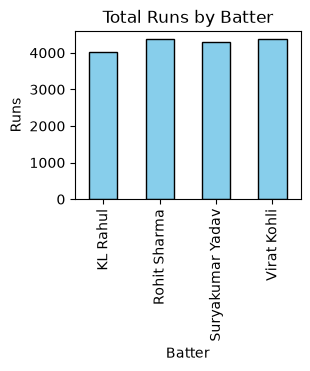

In [60]:
plt.subplot(2, 2, 1)
df.groupby('Batter')['Runs_Scored'].sum().drop('None', errors='ignore').plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Total Runs by Batter')
plt.ylabel('Runs')

####  ...Pie Chart

Text(0, 0.5, '')

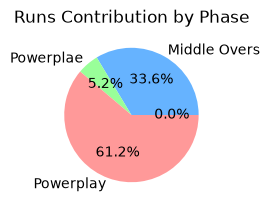

In [61]:
plt.subplot(2, 2, 2)
phase_analysis.plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Runs Contribution by Phase')
plt.ylabel('')

##### ...Line Chart

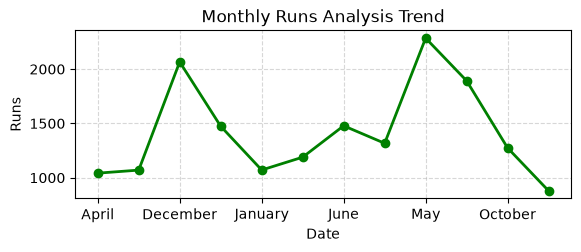

In [ ]:


# Now run the plot smoothly
plt.subplot(2, 1, 2)
monthly_analysis.plot(kind='line', marker='o', color='green', linewidth=2)
plt.title('Monthly Runs Analysis Trend')
plt.ylabel('Runs')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
